# plot_01b. ERA5: the tests at the point (figures)

Drawn from what calc_03a and calc_03b saved, so nothing slow runs. calc_03a saved each statistic's values as they are, every member's and ERA5's; where ERA5 falls among the members (its percentile, p-value and verdict) is worked out here from them, step by step in *Where ERA5 Falls among the Members*. Then the toy ensembles (section 1), the moment test and other statistics (4), the rank histograms (5) and every model's scorecard (6).

Sections 2 and 3 are in plot_01a, 7 and 8 (the maps) in plot_01c, and the observed change in plot_01d.

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from plotting_modules import formatting
from plotting_modules.constants import SEASONS
from extant import era5_evaluation as ev
from extant.config import VARIABLES
from extant.logger import setup_logging
from extant.plots import charts, era5_evaluation as evp, forced_response as fr

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [2]:
%matplotlib inline

## Settings

In [3]:
#(t): As in calc_03a and calc_03b: the variable (its name and units), and the grid point and its label
VARIABLE = VARIABLES['tas']
SAMPLE_LAT_LON = dict(lat=-82.5, lon=120.0)
POINT_LABEL = formatting.format_latlon(SAMPLE_LAT_LON)

#(t): The model of the one-model figures
EXAMPLE_MODEL = 'CanESM5'

In [4]:
#(t): Where calc_03a to calc_03c saved their results: JASMIN's scratch
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SCRATCH_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt')

## Which Results

Run **one** of the next two sections: each sets the folder the results are opened from, the sample's or the full data's.

### Sample data

In [5]:
#(t): The sample's results
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

In [6]:
#(t): The full data's results
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

## Open the Results

First what calc_03a to calc_03c saved in `RESULTS_DIR`, then each result opened.

In [7]:
#(t): What calc_03a to calc_03c saved in RESULTS_DIR
RESULTS_DIR, sorted(path.name for path in RESULTS_DIR.glob('*.zarr'))

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full'),
 ['anomaly_ranks.zarr',
  'demo_anomaly_ranks.zarr',
  'demo_detrended_ranks.zarr',
  'demo_plume.zarr',
  'demo_statistics.zarr',
  'demo_tests.zarr',
  'detections.zarr',
  'detrended_ranks.zarr',
  'era5_kurtosis.zarr',
  'era5_lower_tail.zarr',
  'era5_mean.zarr',
  'era5_point.zarr',
  'era5_regional.zarr',
  'era5_regional_trend.zarr',
  'era5_skewness.zarr',
  'era5_std.zarr',
  'era5_trend.zarr',
  'era5_upper_tail.zarr',
  'era5_width.zarr',
  'eval_map_table.zarr',
  'eval_table.zarr',
  'experiment_noise.zarr',
  'final_mean.zarr',
  'final_quantiles.zarr',
  'first_look.zarr',
  'forced.zarr',
  'hist_nat_final_quantiles.zarr',
  'histnat_point.zarr',
  'historical_kurtosis.zarr',
  'historical_lower_tail.zarr',
  'historical_mean.zarr',
  'historical_point.zarr',
  'historical_skewness.zarr',
  'historical_std.zarr',
  'historical_trend.zarr',
  'historical_upper_tail.zarr',
  'historical_width.zarr',
  'mean_

In [9]:
#(t): At the point: each model's historical members, /<model>/historical
historical_point_tree = xr.open_datatree(RESULTS_DIR / 'historical_point.zarr', engine='zarr').load()

In [11]:
#(t): ... and ERA5
era5_point_da = xr.open_zarr(RESULTS_DIR / 'era5_point.zarr')['tas'].load()

In [ ]:
#(t): Every statistic notebook calc_03a saved, in one store, each a variable named after it: every member's in
#(t): /<model>/historical (on member, season, lat, lon), ERA5's in /ERA5 (on season, lat, lon)
statistics_path = RESULTS_DIR / 'statistics.zarr'
statistics_path

In [ ]:
statistics_tree = xr.open_datatree(statistics_path, engine='zarr').load()

In [ ]:
#(t): The models' members, /<model>/historical
historical_statistics_tree = statistics_tree.match('*/historical')

In [ ]:
#(t): ... and ERA5's
era5_statistics_ds = statistics_tree['ERA5'].to_dataset().load()

In [20]:
#(t): ... the rank histograms of the raw values
raw_ranks_tree = xr.open_datatree(RESULTS_DIR / 'raw_ranks.zarr', engine='zarr').load()

In [21]:
#(t): ... of the anomalies
anomaly_ranks_tree = xr.open_datatree(RESULTS_DIR / 'anomaly_ranks.zarr', engine='zarr').load()

In [22]:
#(t): ... and of the detrended anomalies
detrended_ranks_tree = xr.open_datatree(RESULTS_DIR / 'detrended_ranks.zarr', engine='zarr').load()

In [23]:
#(t): Every test's percentile and verdict, on (model, statistic, season)
eval_table_ds = xr.open_zarr(RESULTS_DIR / 'eval_table.zarr').load()

In [24]:
#(t): The rank test step by step: EXAMPLE_MODEL's anomalies in one season
rank_anatomy_ds = xr.open_zarr(RESULTS_DIR / 'rank_anatomy_data.zarr').load()

In [25]:
#(t): ... and the test
anatomy_result_ds = xr.open_zarr(RESULTS_DIR / 'rank_anatomy_test.zarr').load()

In [26]:
#(t): The toy ensembles: every member's and pseudo-ERA5's mean, trend, standard deviation and width
demo_statistics_ds = xr.open_zarr(RESULTS_DIR / 'demo_statistics.zarr').load()

In [27]:
#(t): ... the rank-histogram tests of the anomalies
demo_anomaly_ranks_ds = xr.open_zarr(RESULTS_DIR / 'demo_anomaly_ranks.zarr').load()

In [28]:
#(t): ... and of the detrended anomalies
demo_detrended_ranks_ds = xr.open_zarr(RESULTS_DIR / 'demo_detrended_ranks.zarr').load()

In [29]:
#(t): ... and the plumes
demo_plume_ds = xr.open_zarr(RESULTS_DIR / 'demo_plume.zarr').load()

## Where ERA5 Falls among the Members

Notebook calc_03a saved each statistic's values as they are: every member's and ERA5's. `ev.locate` places ERA5's value among the members': ERA5's **percentile** among them (ties count half), the two-sided **p-value** (twice the smaller tail, ERA5 counted as one more member: 2 × (members at or beyond ERA5 on that side + 1) / (N + 1)), the **verdict** (−1 ERA5 below the members, +1 above, 0 not flagged; flagged when p < 0.1, i.e. ERA5 outside the members' 5–95%), whether the model has enough members to flag anything at all (**testable**: N ≥ 20), and the members' 5%, 50% and 95% for the figures. First step by step, then for every model, statistic and season at the point; notebook plot_01c's section 7 does the same at every grid point.

**How `ev.locate` places ERA5 among the members**, step by step on EXAMPLE_MODEL's DJF means at the point. Every test in this notebook and in calc_03b's table ends with it, so these steps give every percentile, p-value and verdict.

In [ ]:
#(t): EXAMPLE_MODEL's members' DJF means at the point, and ERA5's
locate_members_da = historical_statistics_tree[EXAMPLE_MODEL]['historical']['mean'].sel(SAMPLE_LAT_LON).sel(season='DJF')
locate_era5_da = era5_statistics_ds['mean'].sel(SAMPLE_LAT_LON).sel(season='DJF')

In [40]:
#(t): How many members there are, how many are less than ERA5, and how many equal it
n_locate_members = int(locate_members_da.notnull().sum())
n_less = int((locate_members_da < locate_era5_da).sum())
n_equal = int((locate_members_da == locate_era5_da).sum())

In [41]:
#(t): ERA5's percentile: the share of the members less than ERA5, a member equal to it counting half
# Example: 4 members [1.0, 2.0, 3.0, 5.0] and ERA5 = 3.0. Two members are less than ERA5 and one equals it.
# The one equal to it counts half, so ERA5 is greater than 2.5 of the 4 members, and its percentile is 100 * 2.5 / 4 = 62.5.
# A perfect model puts ERA5 at any percentile from 0 to 100 equally often.
locate_percentile = 100 * (n_less + 0.5 * n_equal) / n_locate_members

In [42]:
#(t): The two tails: with ERA5 as one more member, the share of the N + 1 values at or less than ERA5, and at or greater
# Example: 20 members, all of them less than ERA5. With ERA5 as one more member there are 21 values.
# All 21 are at or less than ERA5, so the lower tail is (20 + 0 + 1) / 21 = 1.
# Only ERA5 itself is at or greater than ERA5, so the upper tail is (20 - 20 + 1) / 21 = 0.048.
# The + 1s are ERA5 counted as one more member, so neither tail can be 0.
lower_tail = (n_less + n_equal + 1) / (n_locate_members + 1)
upper_tail = (n_locate_members - n_less + 1) / (n_locate_members + 1)

In [43]:
#(t): The two-sided p-value: twice the smaller tail, at most 1
# In the example, twice 0.048 is 0.095.
locate_pvalue = min(2 * min(lower_tail, upper_tail), 1)

In [44]:
#(t): The verdict: flagged when the p-value is less than ALPHA (0.1), -1 if ERA5 is less than the members' middle and +1 if greater
# In the example, 0.095 is less than 0.1 and ERA5's percentile is 100, so the verdict is +1.
# With 19 members, even ERA5 greater than all of them gives 2 / 20 = 0.1, which is not less than 0.1, so nothing can ever
# be flagged: testable is False, and a verdict of 0 then means "untestable", not "consistent".
locate_verdict = int(np.sign(locate_percentile - 50)) if locate_pvalue < ev.ALPHA else 0
locate_testable = 2 / (n_locate_members + 1) < ev.ALPHA

In [45]:
#(t): Check: the steps against ev.locate
locate_check_ds = ev.locate(locate_members_da, locate_era5_da)
pd.DataFrame({'step by step': [locate_percentile, locate_pvalue, locate_verdict, locate_testable],
              'ev.locate': [float(locate_check_ds['percentile']), float(locate_check_ds['pvalue']),
                            int(locate_check_ds['verdict']), bool(locate_check_ds['testable'])]},
             index=['percentile', 'pvalue', 'verdict', 'testable'])

,step by step,ev.locate
percentile,0.0,0.0
pvalue,0.030303,0.030303
verdict,-1,-1
testable,True,True


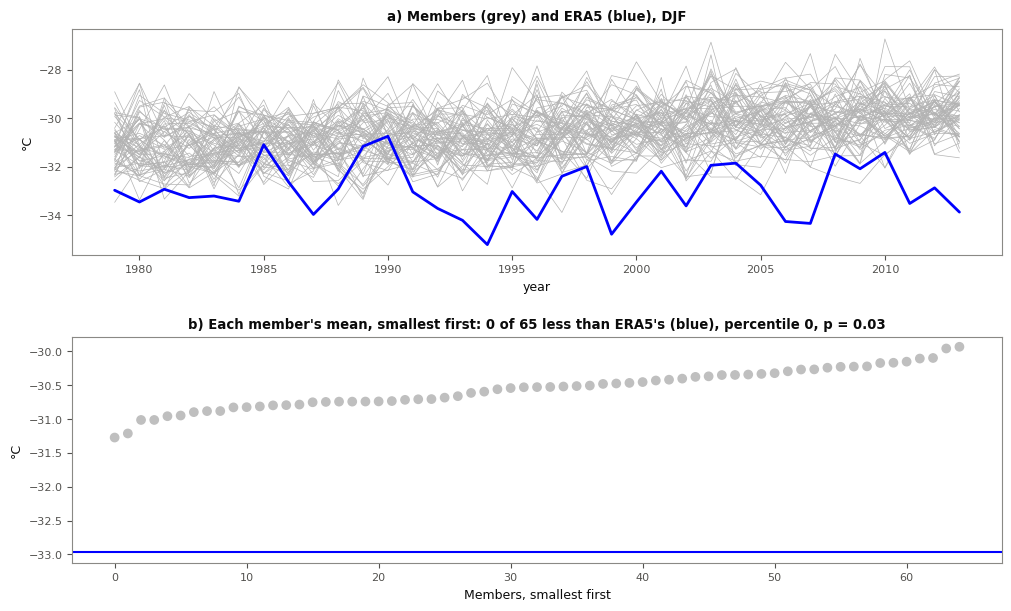

In [46]:
#(t): ev.locate step by step on EXAMPLE_MODEL's DJF means: a) the members (grey) and ERA5 (blue) through the years, the
#(t): series the means are of; b) each member's mean, smallest first, dark where less than ERA5's (blue)
sorted_member_means_arr = np.sort(locate_members_da.values)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), layout='constrained')
historical_point_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].sel(season='DJF').plot.line(ax=ax1, x='year', hue='member',
                                                                                      add_legend=False, color='0.7',
                                                                                      lw=0.5)
era5_point_da.sel(season='DJF').plot(ax=ax1, color='blue', linewidth=2)
ax1.set(title='a) Members (grey) and ERA5 (blue), DJF', ylabel=VARIABLE.units)
ax2.scatter(np.arange(n_locate_members), sorted_member_means_arr,
            color=np.where(sorted_member_means_arr < float(locate_era5_da), '0.25', '0.75').tolist())
ax2.axhline(float(locate_era5_da), color='blue')
ax2.set(title=f"b) Each member's mean, smallest first: {n_less} of {n_locate_members} less than ERA5's (blue), "
              f"percentile {locate_percentile:.0f}, p = {locate_pvalue:.2f}",
        xlabel='Members, smallest first', ylabel=VARIABLE.units);

### Every model at the point

Each statistic at `SAMPLE_LAT_LON`: ERA5's value among each model's members' (`ev.locate`, as above), all eight at once along a `statistic` dim, then the moment test's four and the other statistics' four, for sections 4 and 6 (plot_01a makes the moment test again for section 2).

In [ ]:
#(t): ERA5's eight at the point, along a statistic dim
era5_point_statistics_da = era5_statistics_ds.sel(SAMPLE_LAT_LON).to_dataarray('statistic')
era5_point_statistics_da

In [ ]:
#(t): Where ERA5's value of each statistic falls among each model's members at the point, all eight at once:
#(t): to_dataarray puts a model's eight variables along a statistic dim, in the same order as ERA5's,
#(t): /<model>/historical, on (statistic, member, season)
point_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node.to_dataset().sel(SAMPLE_LAT_LON).to_dataarray('statistic'), era5_point_statistics_da)
    for node in historical_statistics_tree.leaves
})

In [ ]:
#(t): The moment test: each model's four
moment_statistics = ['mean', 'std', 'skewness', 'kurtosis']
moment_test_tree = point_test_tree.sel(statistic=moment_statistics)

In [52]:
#(t): With the values each moment was worked out on, for the figures' labels
moment_test_tree = xr.DataTree.from_dict({
    node.path: node.to_dataset().assign_coords(treatment=('statistic', ['raw', 'detrended', 'detrended', 'detrended']))
    for node in moment_test_tree.leaves
})
moment_test_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:     (statistic: 4, season: 4, member: 65)
│           Coordinates:
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat         float64 8B -82.5
│             * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 8kB -30.53 ... -0.4231
│               lower       (statistic, season) float64 128B -31.0 -58.55 ... -0.9818 -1.007
│               median      (statistic, season) float64 128B -30.53 -58.08 ... -0.3695
│               upper       (statistic, season) float64 128B -30.12 -57.55 ... 1.034 0.6424
│               percentile  (statistic, season) float64 128B 0.0 100.0 100.0 ... 70.77 30.77
│               pvalue      (statistic, season) float64 128B 0.0303 0.0303 ... 0.6061 0.6364
│               verdict     (statistic, season) float64 128B -1.0 1.0 1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:     (statistic: 4, season: 4, member: 63)
│           Coordinates:
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat         float64 8B -82.5
│             * member      (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 8kB -273.1 -273.1 ... nan
│               lower       (statistic, season) float64 128B -273.1 -273.1 ... -1.125
│               median      (statistic, season) float64 128B -33.27 -60.47 ... -0.235
│               upper       (statistic, season) float64 128B -32.26 -59.65 ... 1.771 1.849
│               percentile  (statistic, season) float64 128B 63.49 100.0 ... 53.33 37.78
│               pvalue      (statistic, season) float64 128B 0.75 0.03125 ... 0.9565 0.7826
│               verdict     (statistic, season) float64 128B 0.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:     (statistic: 4, season: 4, member: 55)
│           Coordinates:
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat         float64 8B -82.5
│             * member      (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 7kB -28.02 -56.41 ... 0.1943
│               lower       (statistic, season) float64 128B -28.02 -56.54 ... -0.9203
│               median      (statistic, season) float64 128B -27.71 -56.09 ... -0.3381
│               upper       (statistic, season) float64 128B -27.32 -55.54 ... 0.9406 0.96
│               percentile  (statistic, season) float64 128B 0.0 100.0 100.0 ... 61.

In [ ]:
#(t): The other statistics: each model's four, with the values each was worked out on
statistic_test_tree = point_test_tree.sel(statistic=['trend', 'width', 'lower_tail', 'upper_tail'])
statistic_test_tree = xr.DataTree.from_dict({
    node.path: node.to_dataset().assign_coords(treatment=('statistic', ['raw', 'detrended', 'detrended', 'detrended']))
    for node in statistic_test_tree.leaves
})
statistic_test_tree

## 1. How the Tests Work: Toy Ensembles

Before trusting the tests on real data, here they are on synthetic ensembles where we *know* what is wrong. `ev.simulate_ensemble` (notebooks calc_03a and calc_03b) makes 50 members and a pseudo-ERA5, 1979–2013, four seasons, each series `trend × decades + noise × N(0, 1)`. Pseudo-ERA5 always has a trend of 0.3 per decade and noise 1; each scenario (`ev.SCENARIOS`) changes one thing about the model:

| Scenario | The model | What the tests should say |
|---|---|---|
| Consistent | identical to ERA5 | nothing flagged, apart from ~10% by chance |
| Too little noise | noise 0.6x | ERA5 often outside the plume; U-shaped histograms; std flagged high |
| Too much noise | noise 1.6x | ERA5 never leaves the plume; dome-shaped histograms; std flagged low |
| Signal too strong | trend 0.9/decade | U shape for anomalies but **flat once detrended**; trend and rank trend flagged |
| Mean-state bias | 2° too warm | raw plume offset; only the mean flagged; every anomaly test passes |

Columns: the raw time series with the plume; the rank histograms of anomalies and of detrended anomalies (bars: pseudo-ERA5; grey bars: the range a perfect model gives); ERA5's percentile for each statistic (✓ inside the grey 5–95% band, ✗ outside).

In [58]:
#(t): Where pseudo-ERA5 falls among each toy ensemble's members (ev.locate), every statistic, scenario and season
demo_tests_ds = ev.locate(demo_statistics_ds['members'], demo_statistics_ds['era5'])
demo_tests_ds

<xarray.Dataset> Size: 38kB
Dimensions:     (statistic: 4, scenario: 5, season: 4, member: 50)
Coordinates:
  * season      (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * scenario    (scenario) object 40B 'Consistent' ... 'Mean-state bias'
  * statistic   (statistic) object 32B 'mean' 'trend' 'std' 'width'
  * member      (member) int64 400B 0 1 2 3 4 5 6 7 ... 42 43 44 45 46 47 48 49
Data variables:
    era5        (statistic, scenario, season) float64 640B 0.3109 ... 3.26
    members     (statistic, scenario, member, season) float64 32kB 0.4471 ......
    lower       (statistic, scenario, season) float64 640B 0.2515 ... 2.293
    median      (statistic, scenario, season) float64 640B 0.5175 ... 3.041
    upper       (statistic, scenario, season) float64 640B 0.7684 ... 3.719
    percentile  (statistic, scenario, season) float64 640B 14.0 88.0 ... 68.0
    pvalue      (statistic, scenario, season) float64 640B 0.3137 ... 0.6667
    verdict     (statistic, scenario, season) float64 640B 0.0 0.0 ... 0.0 0.0
    testable    (statistic, scenario, season) float64 640B 1.0 1.0 ... 1.0 1.0

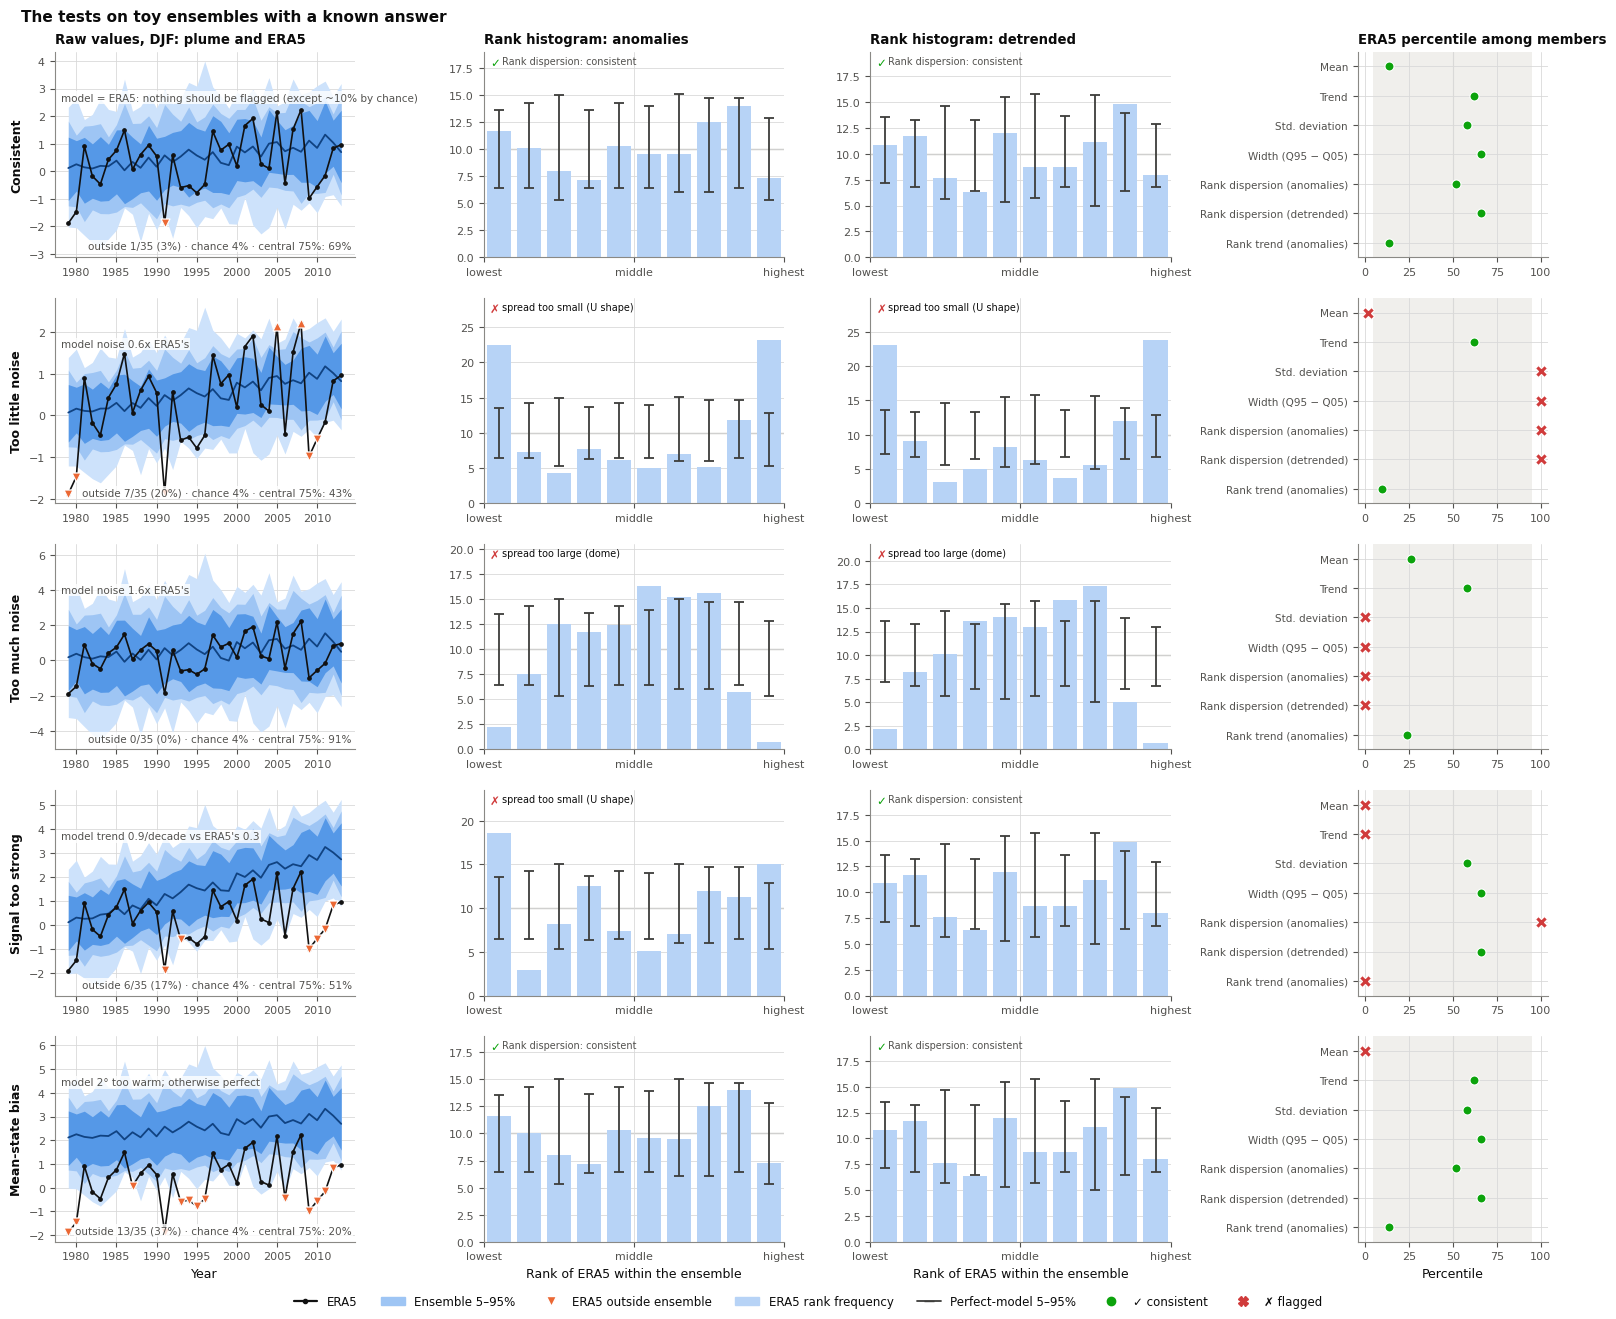

In [59]:
#(t): The tests on toy ensembles with a known answer, one scenario per row: the raw values in DJF with the plume (the
#(t): toy seasons are alike, so one is shown), the
#(t): rank histograms of anomalies and of detrended anomalies, and ERA5's percentile for each statistic (green: inside
#(t): the members' central range; red cross: flagged). The ladder is a block of its own, for room for its labels
scenarios = list(demo_plume_ds['scenario'].values)
fig = plt.figure(figsize=(15.5, 2.3 * len(scenarios) + 1.6), layout='constrained')
#(c): The three columns of panels, and the ladder beside them
grid = fig.add_gridspec(1, 2, width_ratios=[3.3, 1])
axes = grid[0].subgridspec(len(scenarios), 3).subplots(squeeze=False)
ladder_axes = grid[1].subgridspec(len(scenarios), 1).subplots(squeeze=False)
for i, scenario in enumerate(scenarios):
    evp.plot_plume(demo_plume_ds.sel(scenario=scenario, season='DJF'), ax=axes[i, 0])
    axes[i, 0].text(0.02, 0.8, ev.SCENARIO_DESCRIPTIONS.get(scenario, ''), transform=axes[i, 0].transAxes, fontsize=7.5,
                    color=evp.INK_2, va='top', zorder=20,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1))
    axes[i, 0].set_ylabel(scenario, fontweight='bold')
    evp.plot_grouped_rank_histogram(demo_anomaly_ranks_ds.sel(scenario=scenario), ax=axes[i, 1],
                                    statistics=('dispersion',))
    evp.plot_grouped_rank_histogram(demo_detrended_ranks_ds.sel(scenario=scenario), ax=axes[i, 2],
                                    statistics=('dispersion',))
    evp.plot_percentile_ladder(demo_tests_ds.sel(scenario=scenario, season='DJF'),
                               demo_anomaly_ranks_ds.sel(scenario=scenario),
                               demo_detrended_ranks_ds.sel(scenario=scenario), ax=ladder_axes[i, 0])

axes[0, 0].set_title('Raw values, DJF: plume and ERA5', loc='left')
axes[0, 1].set_title('Rank histogram: anomalies', loc='left')
axes[0, 2].set_title('Rank histogram: detrended', loc='left')
ladder_axes[0, 0].set_title('ERA5 percentile among members', loc='left')
axes[-1, 0].set_xlabel('Year')
for ax in axes[-1, 1:]:
    ax.set_xlabel('Rank of ERA5 within the ensemble')
ladder_axes[-1, 0].set_xlabel('Percentile')
fig.legend(handles=evp.scenario_legend_handles(), loc='outside lower center', ncols=7, frameon=False)
fig.suptitle('The tests on toy ensembles with a known answer', x=0.01, ha='left');

**Reading the figure**
- **Signal vs noise.** Compare the two rank-histogram columns. A noise problem (rows 2–3) shows in both. A signal problem (row 4) shows only for anomalies: a trend mismatch pushes ERA5 out of the ensemble at both ends of the record, which looks like a U, and detrending removes it.
- **Raw values vs anomalies.** A mean-state bias (row 5) puts ERA5 outside the raw plume much of the time, but once each series is measured from its own mean, every test passes. This is the "raw values don't fit but the anomalies do" case.
- **Too little noise can also flag the mean.** A too-narrow ensemble underestimates how far a 35-year mean can wander. So read the noise tests first.

**Calibration**

Over 200 random toy worlds (40 members), a perfect model is flagged 6–12% of the time for every statistic (nominally 10%). Each fault is caught by its intended test almost every time:

| | noise too small | noise too large | signal too strong | mean bias |
|---|---|---|---|---|
| std (detrended) | 99% | 97% | 10% | 10% |
| width, Q95 − Q05 | 96% | 92% | – | – |
| cold / warm tail | 76% / 77% | 57% / 59% | – | – |
| rank dispersion (anomalies) | 100% | 100% | 68% | 6% |
| rank dispersion (detrended) | 100% | 100% | 8% | 8% |
| trend | 35% | 2% | 96% | 12% |
| rank trend | 21% | 4% | 100% | 9% |
| mean | 30% | 2% | 100% | 100% |

The tail tests are the weakest: with ~35 values per season, each tail rests on about two of them. A ✓ for a tail therefore means "no evidence of a problem", which is weaker than a ✓ for the width or std.

## 4. Moment Test and Other Statistics

Each panel is one statistic in one season: every member's value is a blue dot, the shading the members' 5–95%, ERA5 the black line and diamond. If the model were perfect, ERA5 would be just another dot; it is flagged (✗) when it falls outside the shading.

In [89]:
#(t): EXAMPLE_MODEL's tests
eval_moments_ds = moment_test_tree[EXAMPLE_MODEL]['historical'].to_dataset()
eval_statistics_ds = statistic_test_tree[EXAMPLE_MODEL]['historical'].to_dataset()
eval_statistics_ds

<xarray.Dataset> Size: 10kB
Dimensions:     (statistic: 4, season: 4, member: 65)
Coordinates:
    lat         float64 8B -82.5
    lon         float64 8B 120.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * statistic   (statistic) <U10 160B 'trend' 'width' 'lower_tail' 'upper_tail'
    treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
Data variables:
    era5        (statistic, season) float64 128B 0.01296 0.1282 ... 2.271 1.786
    members     (statistic, member, season) float64 8kB -0.04846 ... 1.522
    lower       (statistic, season) float64 128B 0.1112 -0.1618 ... 1.373 1.304
    median      (statistic, season) float64 128B 0.4332 0.3684 ... 2.072 1.904
    upper       (statistic, season) float64 128B 0.6944 0.7645 ... 2.794 2.799
    percentile  (statistic, season) float64 128B 1.538 21.54 0.0 ... 66.15 40.0
    pvalue      (statistic, season) float64 128B 0.06061 0.4545 ... 0.697 0.8182
    verdict     (statistic, season) float64 128B -1.0 0.0 -1.0 ... 0.0 0.0 0.0
    testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0

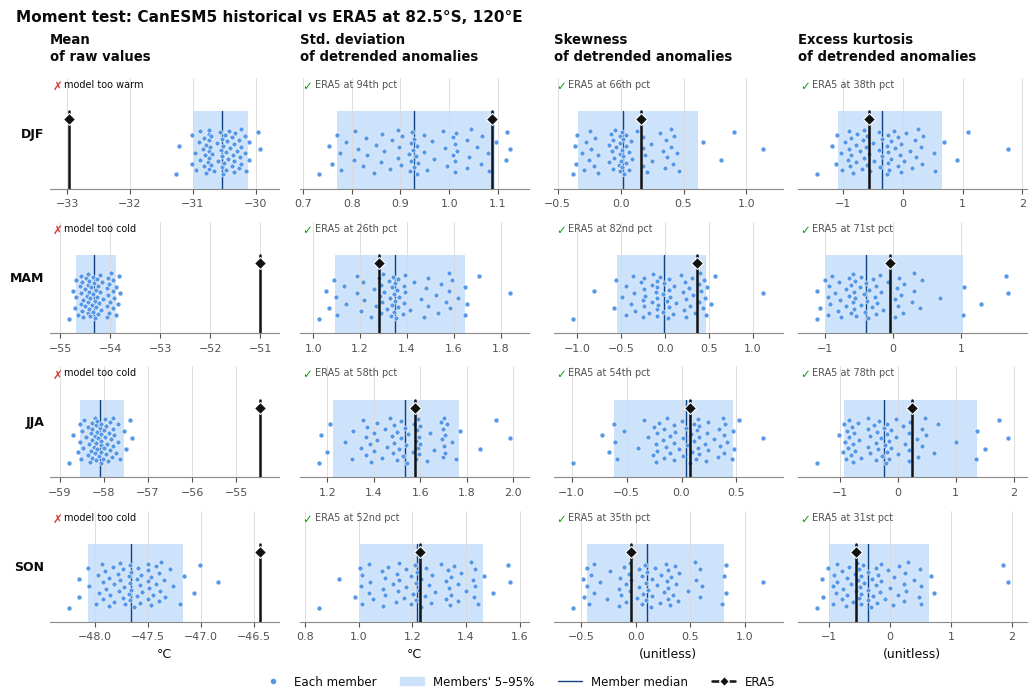

In [90]:
#(t): The moment test: each statistic (columns) in each season (rows), every member a dot and ERA5 the black line, with
#(t): each panel's verdict
moment_statistics = list(eval_moments_ds['statistic'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=len(moment_statistics), n_legends=1,
                                                  panel_width=2.0, panel_height=0.9), layout='constrained')
axes = fig.add_gridspec(len(SEASONS), len(moment_statistics)).subplots(squeeze=False)
evp.member_strips_grid(eval_moments_ds.sel(season=SEASONS), 'season', axes=axes)
for ax, statistic in zip(axes[0], moment_statistics):
    ax.set_title(evp.statistic_title(eval_moments_ds, statistic), loc='left', pad=13)
for ax, statistic in zip(axes[-1], moment_statistics):
    ax.set_xlabel(ev.DIAGNOSTICS[statistic].units or '(unitless)')
for ax, season in zip(axes[:, 0], SEASONS):
    ax.set_ylabel(season, rotation=0, ha='right', va='center', fontweight='bold')
fig.legend(handles=evp.member_strip_legend_handles(), loc='outside lower center', ncols=4, frameon=False)
fig.suptitle(f'Moment test: {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

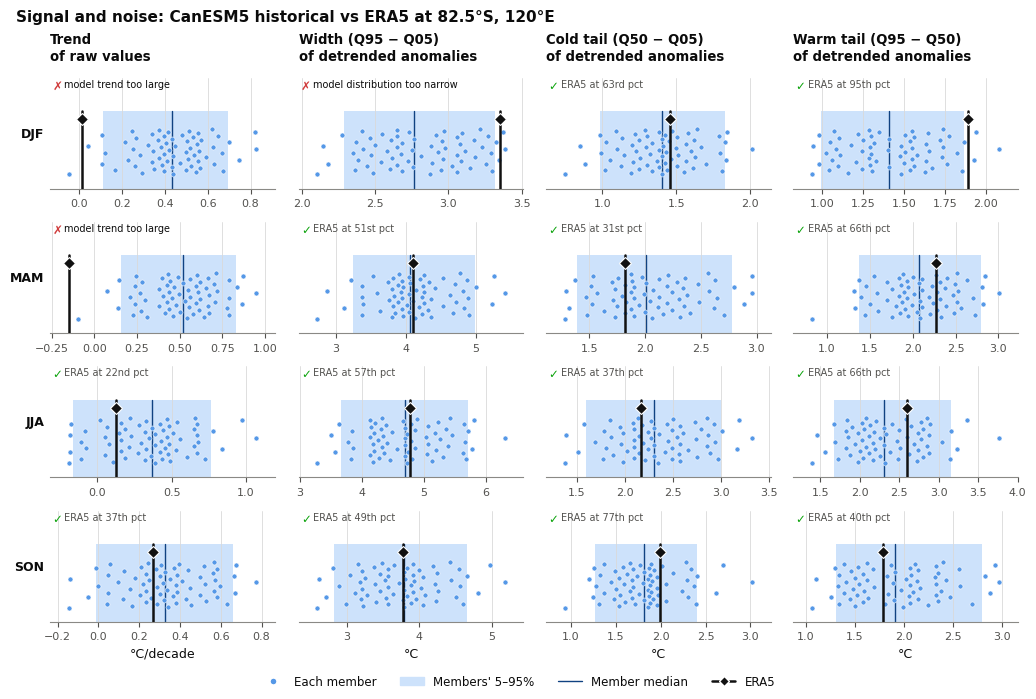

In [91]:
#(t): The signal and noise statistics (the quantities the response figures use)
signal_statistics = ['trend', 'width', 'lower_tail', 'upper_tail']
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=len(signal_statistics), n_legends=1,
                                                  panel_width=2.0, panel_height=0.9), layout='constrained')
axes = fig.add_gridspec(len(SEASONS), len(signal_statistics)).subplots(squeeze=False)
evp.member_strips_grid(eval_statistics_ds.sel(season=SEASONS), 'season', axes=axes, statistics=signal_statistics)
for ax, statistic in zip(axes[0], signal_statistics):
    ax.set_title(evp.statistic_title(eval_statistics_ds, statistic), loc='left', pad=13)
for ax, statistic in zip(axes[-1], signal_statistics):
    ax.set_xlabel(ev.DIAGNOSTICS[statistic].units or '(unitless)')
for ax, season in zip(axes[:, 0], SEASONS):
    ax.set_ylabel(season, rotation=0, ha='right', va='center', fontweight='bold')
fig.legend(handles=evp.member_strip_legend_handles(), loc='outside lower center', ncols=4, frameon=False)
fig.suptitle(f'Signal and noise: {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

## 5. Rank Histograms (Suarez-Gutierrez et al., 2021)

calc_03b goes through the test step by step. Bars are ERA5's rank frequencies; the dashed lines bound the pseudo-observations', the range a perfect model's histogram falls in. A U shape means too little spread (or a wrong trend pushing ERA5 out at both ends), a dome too much. The same U in anomalies and detrended anomalies is a noise problem; a U in anomalies only is a signal problem.

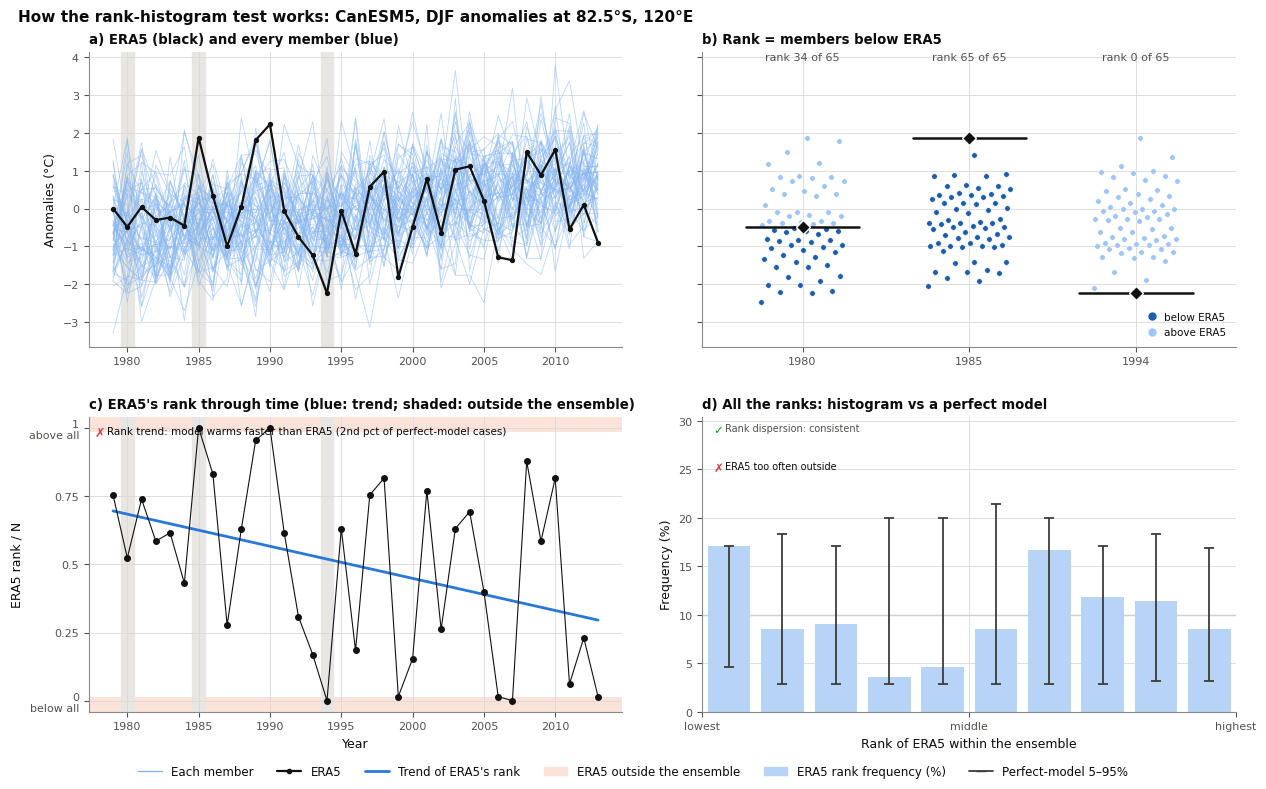

In [92]:
#(t): How the rank-histogram test works, for EXAMPLE_MODEL's anomalies at the point in the example season: a) ERA5 and
#(t): the members through time,
#(t): three instructive years shaded; b) in those years, ERA5's rank is the number of members below it; c) ERA5's rank
#(t): through the record, and its trend; d) every year's rank, counted into a histogram, against a perfect model's
anatomy_members_da = rank_anatomy_ds['members']
anatomy_era5_da = rank_anatomy_ds['era5']
highlighted_years = evp.anatomy_years(anatomy_result_ds)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=2, n_cols=2, n_legends=1, panel_width=5.6, panel_height=2.8),
                 layout='constrained')
axes = fig.add_gridspec(2, 2).subplots(squeeze=False)

#(c): a) the members and ERA5, with the three years shaded
charts.plot_lines(anatomy_members_da, 'year', ax=axes[0, 0], color=evp.ENSEMBLE['member'], linewidth=0.6, alpha=0.55)
charts.plot_lines(anatomy_era5_da, 'year', ax=axes[0, 0], color=evp.ERA5_COLOR, linewidth=1.6, marker='o',
                  markersize=2.8, zorder=3)
for year in highlighted_years:
    axes[0, 0].axvspan(year - 0.45, year + 0.45, color='#e7e6e2', zorder=0)
treatment = str(anatomy_result_ds['treatment'].values[0])
axes[0, 0].set_ylabel(f'{ev.TREATMENTS[treatment]} ({VARIABLE.units})')
axes[0, 0].set_title('a) ERA5 (black) and every member (blue)', loc='left')
#(c): b) ranking ERA5 in each of the three years
evp.plot_rank_counting(anatomy_members_da, anatomy_era5_da, highlighted_years, ax=axes[0, 1])
#(c): On a's y axis, so each year's values line up with a's
axes[0, 1].sharey(axes[0, 0])
axes[0, 1].tick_params(axis='y', labelleft=False)
axes[0, 1].set_title('b) Rank = members below ERA5', loc='left')
#(c): c) ERA5's rank through time
evp.plot_rank_through_time(anatomy_result_ds, highlighted_years, ax=axes[1, 0])
axes[1, 0].set_ylabel('ERA5 rank / N')
axes[1, 0].set_xlabel('Year')
axes[1, 0].set_title("c) ERA5's rank through time (blue: trend; shaded: outside the ensemble)", loc='left')
#(c): d) all the ranks, in 10 bins of rank / N (~35 ranks over N bins would be sparse)
evp.plot_grouped_rank_histogram(anatomy_result_ds, ax=axes[1, 1], n_bins=10, statistics=('dispersion', 'outside'))
axes[1, 1].set_ylabel('Frequency (%)')
axes[1, 1].set_xlabel('Rank of ERA5 within the ensemble')
axes[1, 1].set_title('d) All the ranks: histogram vs a perfect model', loc='left')

fig.legend(handles=[
Line2D([], [], color=evp.ENSEMBLE['member'], lw=1, label='Each member'),
Line2D([], [], color=evp.ERA5_COLOR, lw=1.6, marker='o', ms=3, label='ERA5'),
Line2D([], [], color=evp.RANK_LINE, lw=2, label="Trend of ERA5's rank"),
Patch(color='#fbe3d9', label='ERA5 outside the ensemble'),
*evp.grouped_rank_legend_handles()[:2],
], loc='outside lower center', ncols=6, frameon=False)
anatomy_season = str(anatomy_members_da['season'].values)
fig.suptitle(f'How the rank-histogram test works: {EXAMPLE_MODEL}, {anatomy_season} anomalies at {POINT_LABEL}', x=0.01,
             ha='left');

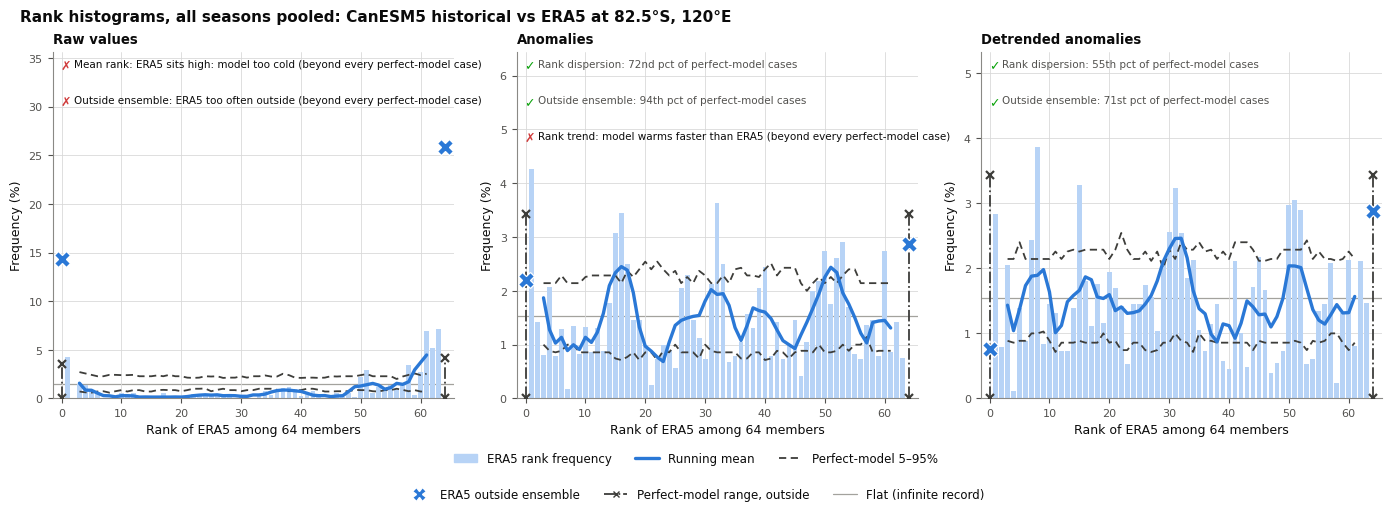

In [93]:
#(t): All four seasons pooled: EXAMPLE_MODEL's rank histograms of the raw values, the anomalies and the detrended
#(t): anomalies,
#(t): side by side, each with its verdicts
model_ranks = {'Raw values': raw_ranks_tree[EXAMPLE_MODEL]['historical'].to_dataset(),
               'Anomalies': anomaly_ranks_tree[EXAMPLE_MODEL]['historical'].to_dataset(),
               'Detrended anomalies': detrended_ranks_tree[EXAMPLE_MODEL]['historical'].to_dataset()}
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(model_ranks), n_legends=2, panel_width=4.0,
                                                  panel_height=3.0), layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(1, len(model_ranks)).subplots(squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for ax, (label, ranks_ds) in zip(axes[0], model_ranks.items()):
    evp.plot_rank_histogram(ranks_ds, ax=ax)
    ax.set_title(label, loc='left')
rank_handles = evp.rank_histogram_legend_handles()
legend_axes[0].legend(handles=rank_handles[:3], loc='center', ncols=3, frameon=False)
legend_axes[1].legend(handles=rank_handles[3:], loc='center', ncols=3, frameon=False)
fig.suptitle(f'Rank histograms, all seasons pooled: {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01,
             ha='left');

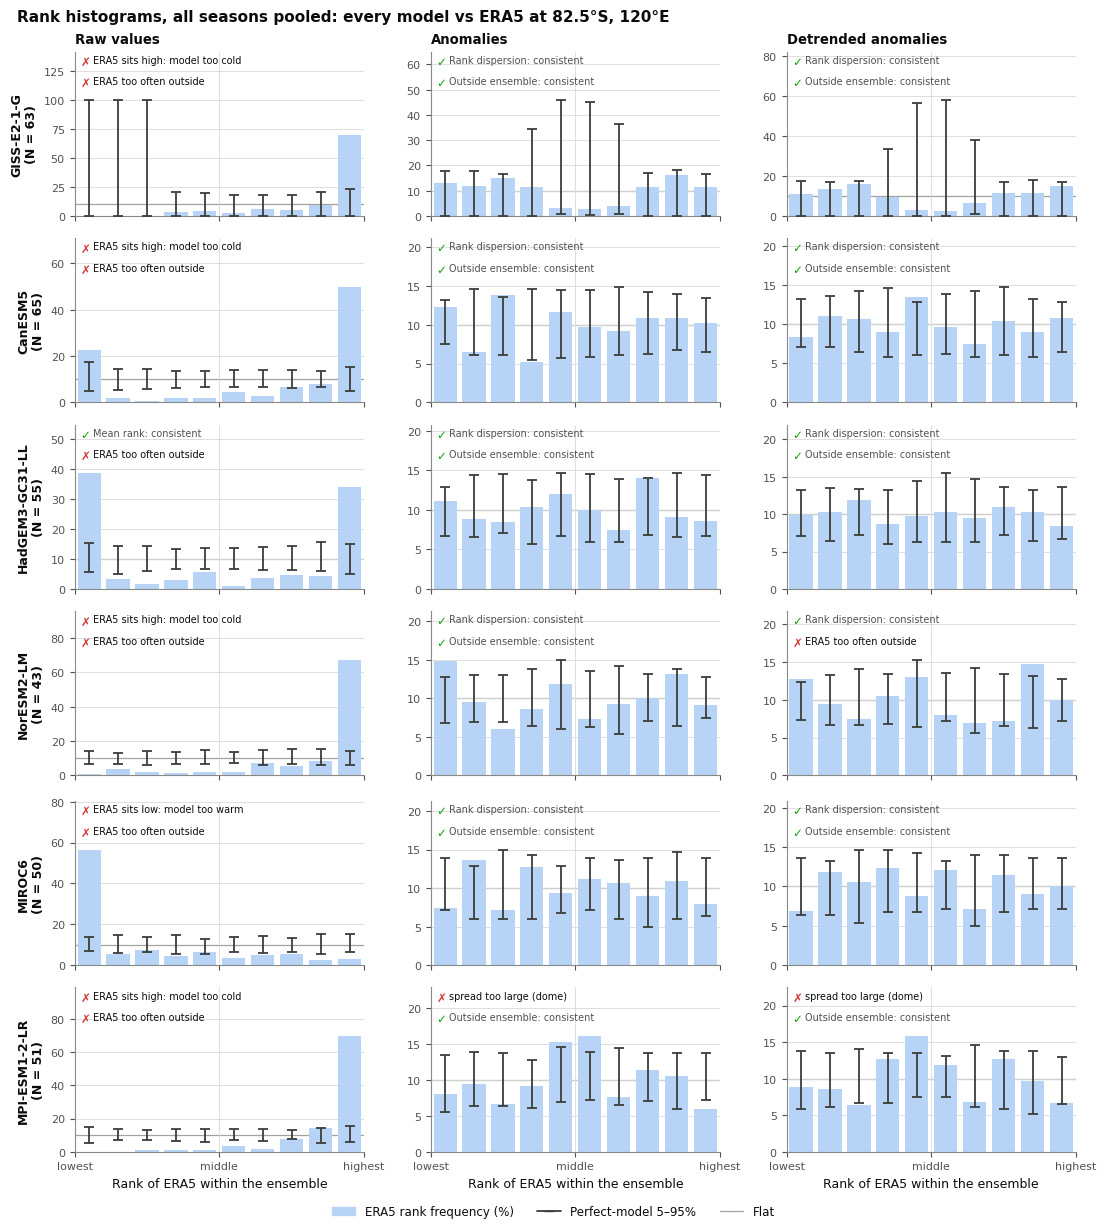

In [94]:
#(t): Every model (rows), compact: ranks grouped into 10 bins of rank / N, so ensembles of any size line up; raw values,
#(t): anomalies and detrended anomalies across
rank_trees = {'Raw values': raw_ranks_tree, 'Anomalies': anomaly_ranks_tree, 'Detrended anomalies': detrended_ranks_tree}
rank_models = [node.parent.name for node in raw_ranks_tree.match('*/historical').leaves]
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(rank_models), n_cols=len(rank_trees), n_legends=1,
                                                  panel_width=2.8, panel_height=1.3, left_margin=1.5),
                 layout='constrained')
axes = fig.add_gridspec(len(rank_models), len(rank_trees)).subplots(sharex=True, squeeze=False)
for i, model in enumerate(rank_models):
    for j, ranks_tree in enumerate(rank_trees.values()):
        evp.plot_grouped_rank_histogram(ranks_tree[model]['historical'].to_dataset(), ax=axes[i, j])
    n_members = raw_ranks_tree[model]['historical'].attrs['n_members']
    axes[i, 0].set_ylabel(f'{model}\n(N = {n_members})', fontweight='bold')
for ax, label in zip(axes[0], rank_trees):
    ax.set_title(label, loc='left')
for ax in axes[-1]:
    ax.set_xlabel('Rank of ERA5 within the ensemble')
fig.legend(handles=evp.grouped_rank_legend_handles(), loc='outside lower center', ncols=3, frameon=False)
fig.suptitle(f'Rank histograms, all seasons pooled: every model vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

## 6. Every Model: Scorecard and Signal vs Noise

**Scorecard.** Colour is ERA5's percentile among that model's members: blue, ERA5 below most members; red, above. Outlined cells are flagged (p < 0.1). Expect about one cell in ten flagged by chance: trust patterns over single cells.

**Signal vs noise.** ERA5's percentile for the trend (x: the signal) against the standard deviation of detrended anomalies (y: the noise). Inside the grey square the model is consistent on both.

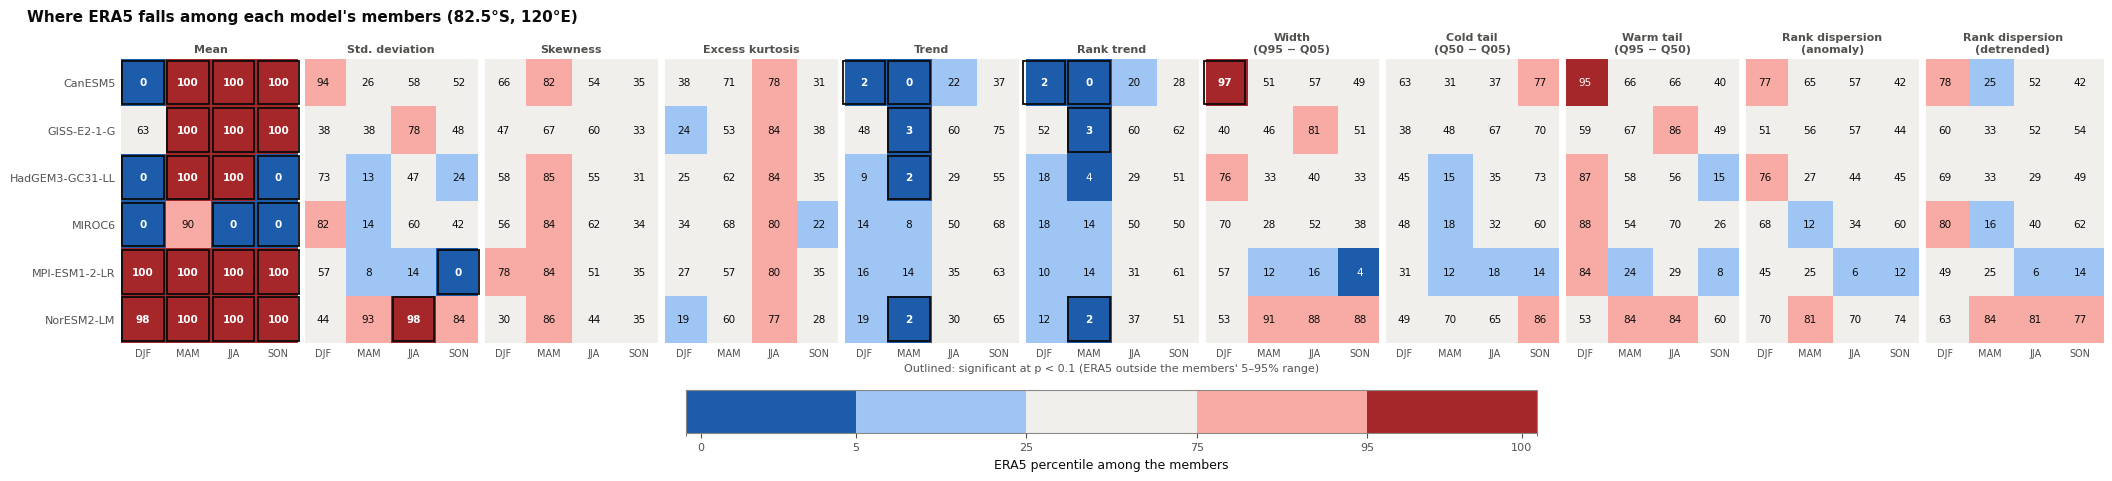

In [95]:
#(t): Every model (rows), statistic and season (columns): ERA5's percentile among the members, outlined where
#(t): significant
SCORECARD_STATISTICS = ['mean', 'std', 'skewness', 'kurtosis', 'trend', 'rank_trend', 'width',
                        'lower_tail', 'upper_tail', 'dispersion (anomaly)', 'dispersion (detrended)']
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.44 * len(SCORECARD_STATISTICS) * len(SEASONS),
                                                  panel_height=0.46 * eval_table_ds.sizes['model'], left_margin=1.5),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
scorecard_image = evp.plot_scorecard(eval_table_ds, statistics=SCORECARD_STATISTICS, ax=axes[0, 0])
fig.colorbar(scorecard_image, ax=axes, location='bottom', shrink=0.6, ticks=evp.PERCENTILE_BOUNDS,
             label='ERA5 percentile among the members')
fig.suptitle(f"Where ERA5 falls among each model's members ({POINT_LABEL})", x=0.01, ha='left');

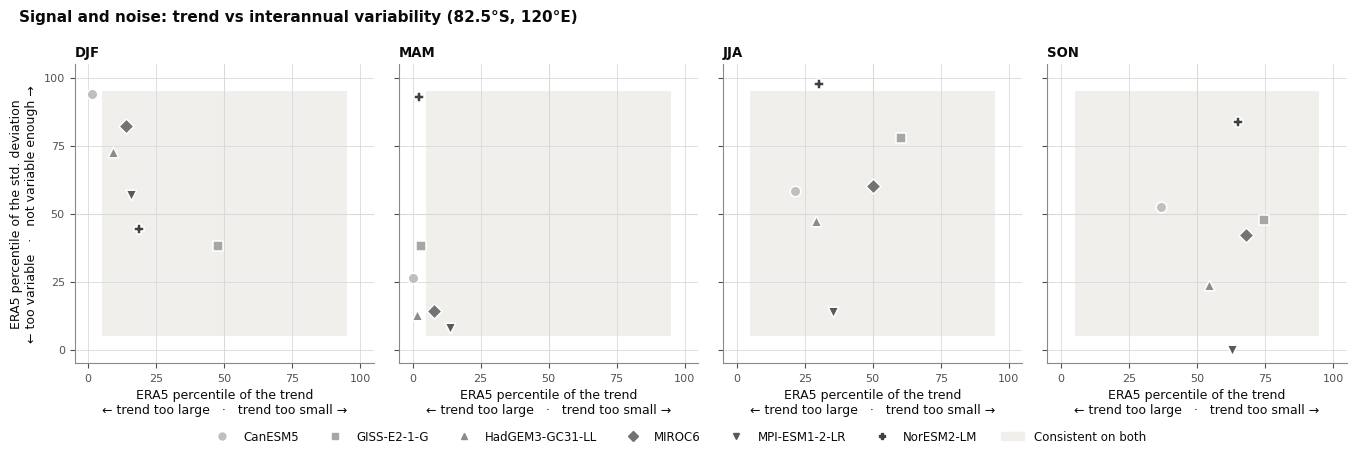

In [96]:
#(t): Signal against noise, every model (its marker and shade of historical's grey), one panel per season: ERA5's
#(t): percentile for the trend (x) and the interannual variability (y); inside the grey square, consistent on both
signal_noise_models = list(eval_table_ds['model'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(SEASONS), n_legends=1, panel_width=2.8,
                                                  panel_height=2.8), layout='constrained')
axes = fig.add_gridspec(1, len(SEASONS)).subplots(sharex=True, sharey=True, squeeze=False)
for ax, season in zip(axes[0], SEASONS):
    evp.plot_signal_noise(eval_table_ds, season, x='trend', y='std', ax=ax)
    ax.set_title(season, loc='left')
    ax.set_xlabel(evp.signal_noise_label('trend'))
axes[0, 0].set_ylabel(evp.signal_noise_label('std'))
fig.legend(handles=charts.model_legend_handles(signal_noise_models, experiment='historical')
           + [Patch(color='#f0efec', label='Consistent on both')],
           loc='outside lower center', ncols=len(signal_noise_models) + 1, frameon=False)
fig.suptitle(f'Signal and noise: trend vs interannual variability ({POINT_LABEL})', x=0.01, ha='left');

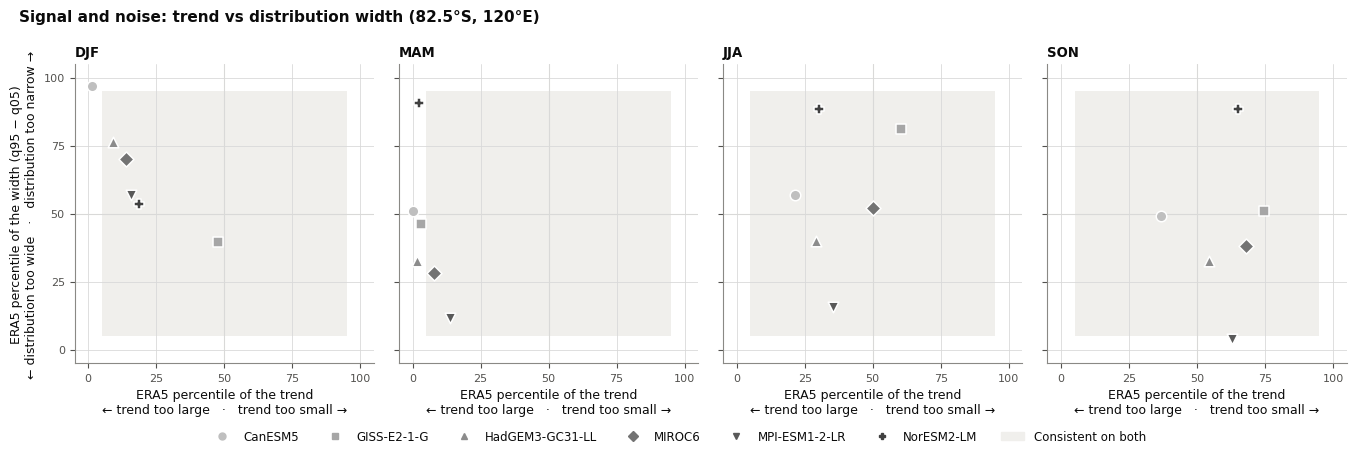

In [97]:
#(t): ... the trend against the distribution's width instead
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(SEASONS), n_legends=1, panel_width=2.8,
                                                  panel_height=2.8), layout='constrained')
axes = fig.add_gridspec(1, len(SEASONS)).subplots(sharex=True, sharey=True, squeeze=False)
for ax, season in zip(axes[0], SEASONS):
    evp.plot_signal_noise(eval_table_ds, season, x='trend', y='width', ax=ax)
    ax.set_title(season, loc='left')
    ax.set_xlabel(evp.signal_noise_label('trend'))
axes[0, 0].set_ylabel(evp.signal_noise_label('width'))
fig.legend(handles=charts.model_legend_handles(signal_noise_models, experiment='historical')
           + [Patch(color='#f0efec', label='Consistent on both')],
           loc='outside lower center', ncols=len(signal_noise_models) + 1, frameon=False)
fig.suptitle(f'Signal and noise: trend vs distribution width ({POINT_LABEL})', x=0.01, ha='left');